# Explore Customer Data with Pandas and Matplotlib

Use the supplied `customer_details.csv` to load, inspect, clean, transform, summarize, and visualize a real table. This notebook is a Week 1 data-analysis lab; it builds on Python values, conditions, collections, and functions.

## Learning goals
- Load a CSV into a Pandas DataFrame and inspect its shape, columns, and values.
- Select columns, filter rows with Boolean masks, and sort records.
- Check missing values and duplicates, convert a column, and create a derived column.
- Group records and calculate useful summary statistics.
- Create and label a bar chart, histogram, and scatter plot with Matplotlib.

## Working method
Before each transformation or plot, state the question it answers. Run the cells in order. Use `Restart Kernel and Run All` if values become inconsistent.

## 1. Import packages and locate the CSV

Pandas provides labeled tables; Matplotlib draws charts. The path check below works when the notebook runs either inside this folder or from the workspace root. If neither path exists, inspect `Path.cwd()` and update `DATA_PATH`.

In [29]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Support running from the notebook folder, workspace root, or legacy course folder.
data_path_candidates = [
    Path("customer_details.csv"),
    Path("PythonBasics") / "customer_details.csv",
    Path("Week - 1 Python Basics") / "customer_details.csv",
]
DATA_PATH = next(
    (path for path in data_path_candidates if path.exists()),
    data_path_candidates[0],
)

print("Working directory:", Path.cwd())
print("CSV path:", DATA_PATH.resolve())
print("CSV found:", DATA_PATH.exists())
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "customer_details.csv was not found. Open the course workspace or update DATA_PATH."
    )

Working directory: /run/media/chitresh/8a6ff761-51df-41f4-b853-3a5fcd07a873/Freelancing/Live_Batches/Agentic_Batch_AI_21st_Nov_2026/PythonBasics
CSV path: /run/media/chitresh/8a6ff761-51df-41f4-b853-3a5fcd07a873/Freelancing/Live_Batches/Agentic_Batch_AI_21st_Nov_2026/PythonBasics/customer_details.csv
CSV found: True


## 2. Load the data

`read_csv` parses the header into column labels and returns a DataFrame. Keep the original table in `df`; later transformations will create named working copies so it is clear which data has changed.

In [30]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 3,900 | Columns: 18


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


## 3. Inspect before analyzing

Use `shape` for dimensions, `columns` for exact labels, `dtypes` for inferred types, and `info()` for a compact null-count overview. `describe()` summarizes numeric columns; `include="all"` also describes non-numeric columns.

In [31]:
print("Shape:", df.shape)
print("Column labels:", df.columns.tolist())
print("Data types:")
print(df.dtypes)
df.info()

Shape: (3900, 18)
Column labels: ['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Payment Method', 'Frequency of Purchases']
Data types:
Customer ID                 int64
Age                         int64
Gender                        str
Item Purchased                str
Category                      str
Purchase Amount (USD)       int64
Location                      str
Size                          str
Color                         str
Season                        str
Review Rating             float64
Subscription Status           str
Shipping Type                 str
Discount Applied              str
Promo Code Used               str
Previous Purchases          int64
Payment Method                str
Frequency of Purchases        str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 3

In [32]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,3900.0,NaN,NaN,NaN,1950.5,1125.977353,1.0,975.75,1950.5,2925.25,3900.0
Age,3900.0,NaN,NaN,NaN,44.068462,15.207589,18.0,31.0,44.0,57.0,70.0
Gender,3900,2,Male,2652,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Purchased,3900,25,Blouse,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,3900,4,Clothing,1737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase Amount (USD),3900.0,NaN,NaN,NaN,59.764359,23.685392,20.0,39.0,60.0,81.0,100.0
Location,3900,50,Montana,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,3900,4,M,1755,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Color,3900,25,Olive,177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,3900,4,Spring,999,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Select rows and columns

Square brackets select one column by name or a subset of columns by a list of names. `.loc[row_condition, columns]` selects rows and columns by labels. Use the exact column spelling shown by `df.columns`; the purchase column includes spaces and parentheses.

In [33]:
# Select one Series, then a DataFrame containing several columns.
purchase_amount = df["Purchase Amount (USD)"]
customer_view = df[["Customer ID", "Age", "Category", "Purchase Amount (USD)"]]
customer_view.head()

,Customer ID,Age,Category,Purchase Amount (USD)
0,1,55,Clothing,53
1,2,19,Clothing,64
2,3,50,Clothing,73
3,4,21,Footwear,90
4,5,45,Clothing,49


## 5. Filter rows with conditions

A comparison creates a Boolean mask with one True/False value per row. Combine multiple masks with `&` for AND or `|` for OR, and put parentheses around each comparison. Do not use Python's `and` or `or` between whole Series.

In [34]:
female_high_spend = df.loc[
    (df["Gender"] == "Female") & (df["Purchase Amount (USD)"] >= 80),
    ["Customer ID", "Item Purchased", "Category", "Purchase Amount (USD)"],
]
print("Matching records:", len(female_high_spend))
female_high_spend.head()

Matching records: 334


,Customer ID,Item Purchased,Category,Purchase Amount (USD)
2655,2656,Sunglasses,Accessories,83
2657,2658,Dress,Clothing,81
2660,2661,Pants,Clothing,85
2661,2662,Boots,Footwear,96
2662,2663,Skirt,Clothing,98


## 6. Sort records

`sort_values` returns rows ordered by a column. Set `ascending=False` to put the largest values first. `head(n)` is a quick way to inspect the first n rows after sorting.

In [35]:
top_purchases = df.sort_values("Purchase Amount (USD)", ascending=False)
top_purchases[["Item Purchased", "Category", "Location", "Purchase Amount (USD)"]].head(10)

,Item Purchased,Category,Location,Purchase Amount (USD)
1479,Coat,Outerwear,Washington,100
1456,Coat,Outerwear,Montana,100
1591,Skirt,Clothing,South Dakota,100
2071,Jacket,Outerwear,South Carolina,100
1421,Dress,Clothing,Pennsylvania,100
1412,Shorts,Clothing,Michigan,100
1405,Socks,Clothing,New Hampshire,100
1847,Sandals,Footwear,Arizona,100
769,Socks,Clothing,Delaware,100
2842,Coat,Outerwear,Arizona,100


## 7. Check and prepare data

Measure missing values and duplicate rows before deciding what to do. Here we make a copy, convert purchase amount safely with `to_numeric`, and remove rows only when that required analysis value is missing. Do not drop data automatically without considering the question.

In [36]:
print("Missing values by column:")
print(df.isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())

analysis_df = df.copy()
analysis_df["Purchase Amount (USD)"] = pd.to_numeric(
    analysis_df["Purchase Amount (USD)"], errors="coerce"
)
analysis_df = analysis_df.dropna(subset=["Purchase Amount (USD)"])
print("Rows retained for purchase analysis:", len(analysis_df))

Missing values by column:
Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64
Exact duplicate rows: 0
Rows retained for purchase analysis: 3900


## 8. Transform columns

`rename` makes long column names easier to use in analysis. `.loc` can assign a derived label to rows that meet a condition. We will classify purchases of at least $75 as High; this is a teaching rule, not a business conclusion.

In [37]:
analysis_df = analysis_df.rename(
    columns={"Purchase Amount (USD)": "Purchase Amount"}
)
analysis_df["Purchase Tier"] = "Standard"
analysis_df.loc[analysis_df["Purchase Amount"] >= 75, "Purchase Tier"] = "High"
analysis_df[["Purchase Amount", "Purchase Tier"]].head()

,Purchase Amount,Purchase Tier
0,53,Standard
1,64,Standard
2,73,Standard
3,90,High
4,49,Standard


## 9. Count and aggregate

`value_counts` counts distinct labels in a Series. `groupby` splits rows by a category, then lets us calculate multiple summaries such as record count, mean, and total. Always read the group sizes alongside the averages.

In [38]:
category_counts = analysis_df["Category"].value_counts()
print(category_counts)

category_summary = (
    analysis_df.groupby("Category")["Purchase Amount"]
    .agg(record_count="size", average_purchase="mean", total_purchase="sum")
    .sort_values("average_purchase", ascending=False)
)
category_summary

Category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64


,record_count,average_purchase,total_purchase
Category,,,
Footwear,599,60.255426,36093
Clothing,1737,60.025331,104264
Accessories,1240,59.838710,74200
Outerwear,324,57.172840,18524


## 10. Bar chart: compare categories

A bar chart compares values across named categories. This chart answers: how many customer records are in each category? Labels and a descriptive title explain what the bars represent.

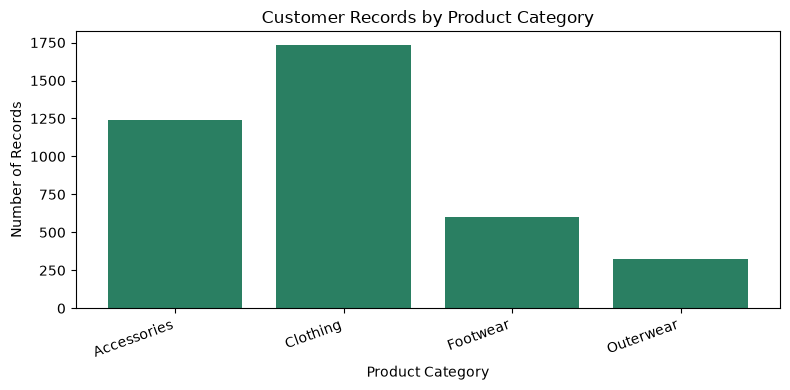

In [39]:
counts_for_plot = category_counts.sort_index()
plt.figure(figsize=(8, 4))
plt.bar(counts_for_plot.index, counts_for_plot.values, color="#2a7f62")
plt.title("Customer Records by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 11. Histogram: inspect a numeric distribution

A histogram groups numeric values into bins. It helps show where purchase amounts are concentrated and how spread out they are. Changing `bins` changes the detail level, not the underlying records.

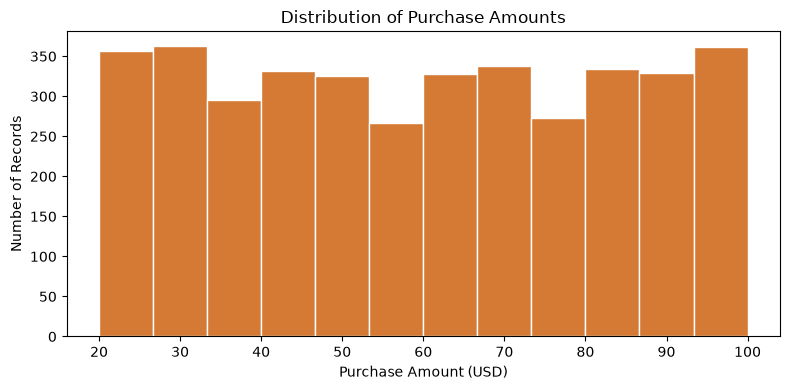

In [40]:
plt.figure(figsize=(8, 4))
plt.hist(analysis_df["Purchase Amount"], bins=12, edgecolor="white", color="#d47a35")
plt.title("Distribution of Purchase Amounts")
plt.xlabel("Purchase Amount (USD)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## 12. Scatter plot: inspect two numeric variables

A scatter plot places one record at each x/y pair. It can reveal a possible relationship or clusters, but a visible pattern alone does not establish cause and effect. Transparency helps when points overlap.

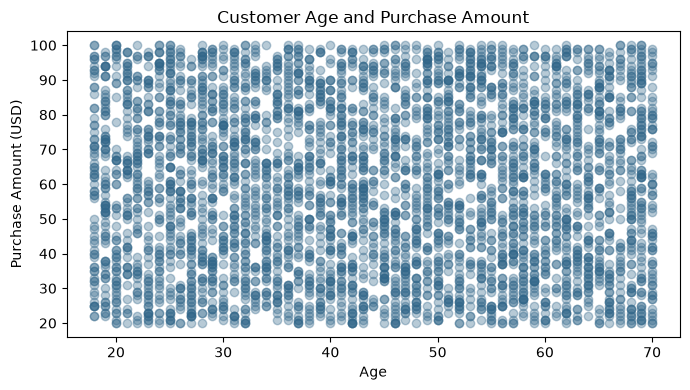

In [41]:
plt.figure(figsize=(7, 4))
plt.scatter(
    analysis_df["Age"],
    analysis_df["Purchase Amount"],
    alpha=0.35,
    color="#32678a",
)
plt.title("Customer Age and Purchase Amount")
plt.xlabel("Age")
plt.ylabel("Purchase Amount (USD)")
plt.tight_layout()
plt.show()

## 13. Practice questions

1. Which season has the most records? Show the count and explain how you found it.
2. What is the average purchase amount by `Subscription Status`? Include the number of records in each group.
3. Create a bar chart of average purchase amount by category. How does this answer a different question from the count chart?
4. Find rows where the review rating is at least 4.0 and the purchase amount is at least $75. How many records match?
5. Which chart would you choose to compare counts by payment method? Which chart would you choose to inspect the age distribution? Explain why.

Add your code and a short interpretation below each question. Avoid claiming causation from a chart.

In [42]:
# Practice 1: count records by Season.


# Practice 2: summarize purchase amount by Subscription Status.


# Practice 3: plot average purchase amount by Category.


# Practice 4: filter on Review Rating and Purchase Amount.

## Conceptual check

Answer in your own words before checking the notebook slides or notes.

1. What do the two values in `df.shape` represent?
2. Why should you inspect `df.columns` before typing a long column label?
3. What is the difference between selecting `df["Age"]` and `df[["Age"]]`?
4. Why do we wrap each comparison in parentheses when combining Pandas masks with `&`?
5. What does `errors="coerce"` do during numeric conversion, and what decision should follow it?
6. In `groupby`, what do the grouping column and aggregation column each control?
7. Which chart would you use to compare category counts? Which to inspect a numeric distribution?
8. Does a scatter plot prove that one variable causes another? Why not?

## Takeaway

Inspect first, transform deliberately, summarize to answer a question, and choose a chart whose visual encoding matches that question.